In [1]:
import sklearn
import pandas as pd
import numpy as np

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X, y = mnist['data'], mnist['target']

X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [3]:
desciption = mnist['DESCR']
print(desciption)

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [4]:
print(f"Shape of dataset: X-shape {X.shape} and y-shape: {y.shape}")

Shape of dataset: X-shape (70000, 784) and y-shape: (70000,)


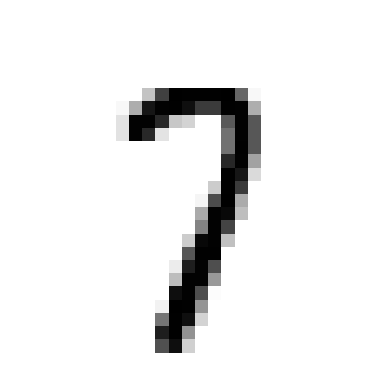

In [5]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

some_digit = X[34600]
some_digit_image = some_digit.reshape(28, 28)

plt.imshow(some_digit_image, cmap=matplotlib.cm.binary, interpolation='nearest')
plt.axis('off')
plt.show()

The MNIST dataset is actually alreayd split into training and testing dataset, 60k and 10k.

In [6]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

## shuffling the dataset for i.i.d

shuffle_index = np.random.permutation(60000)
X_train, y_train = X_train[shuffle_index], y_train[shuffle_index]

Now let us train a binary classifier, simplifying problem by making it identify one digit for example 7 detector. let us create the target vectors for our classification

In [7]:
# Convert target labels from strings to integers first
y_train = y_train.astype(int)
y_test = y_test.astype(int)

# Now create your binary mask
y_tr_2 = (y_train == 2)
y_test_2 = (y_test == 2)

# Verify again
import numpy as np
print("Training target class distribution:", np.unique(y_tr_2, return_counts=True))

Training target class distribution: (array([False,  True]), array([54042,  5958]))


In [8]:
## Using SGD for classification
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_tr_2)
sgd_clf.predict([some_digit])

array([False])

Performance Measures for classification.

In [9]:
##measuring accuracy using Cross validation
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3)
for train_index, test_index in skfolds.split(X_train, y_tr_2):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_tr_2[train_index]
    X_test_folds = X_train[test_index]
    y_test_folds = y_tr_2[test_index]


    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_folds)
    n_correct = sum(y_pred == y_test_folds)
    print(n_correct/ len(y_pred))


0.95465
0.9648
0.87465


Let us use cross val function to evaluate SGDclassifier model using K-fold cross validation, with three folds

In [10]:
from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_tr_2, cv=3, scoring='accuracy')


array([0.95465, 0.9648 , 0.87465])

In [11]:
from sklearn.base import BaseEstimator

class Never2Classifier(BaseEstimator):
    def fit(self, X, y=None):
        pass

    def predict(self, X):
        return np.zeros((len(X), 1), dtype=bool)

never_2_clf = Never2Classifier()
cross_val_score(never_2_clf, X_train, y_tr_2, cv=3, scoring='accuracy')

array([0.9   , 0.899 , 0.9031])

Confusion Matrix:

In [12]:
from sklearn.model_selection import cross_val_score
y_train_pred = cross_val_score(sgd_clf, X_train, y_tr_2, cv=3)

In [13]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, X_train, y_tr_2, cv=3)
confusion_matrix(y_tr_2, y_train_pred)

array([[50387,  3655],
       [  463,  5495]])

In [14]:
from sklearn.metrics import precision_score, recall_score
precision_score(y_tr_2, y_train_pred)

0.6005464480874317

In [15]:
recall_score(y_tr_2, y_train_pred)

0.9222893588452501

In [16]:
from sklearn.metrics import f1_score
f1_score(y_tr_2, y_train_pred)


0.7274291765951814

In [17]:
y_scores = sgd_clf.decision_function([some_digit])
print(y_scores)

[-421.11094856]


In [18]:
threshold = 20000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False])

In [19]:
y_scores = cross_val_predict(sgd_clf, X_train, y_tr_2, cv=3, method='decision_function')
y_scores

array([-10125.35913272,  -7655.62788474, -21561.98759569, ...,
       -37316.10257982, -13535.38111865,   3123.67010841], shape=(60000,))

In [20]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds, = precision_recall_curve(y_tr_2, y_scores)

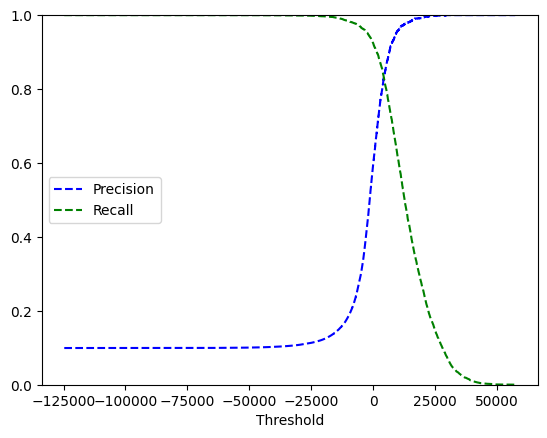

In [21]:
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label='Precision')
    plt.plot(thresholds, recalls[:-1], 'g--', label="Recall")
    plt.xlabel("Threshold")
    plt.legend(loc='center left')
    plt.ylim([0, 1])

plot_precision_recall_vs_threshold(precisions, recalls, thresholds)
plt.show()

ROC curve: reciever operating characteristics: 

In [23]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_tr_2, y_scores)

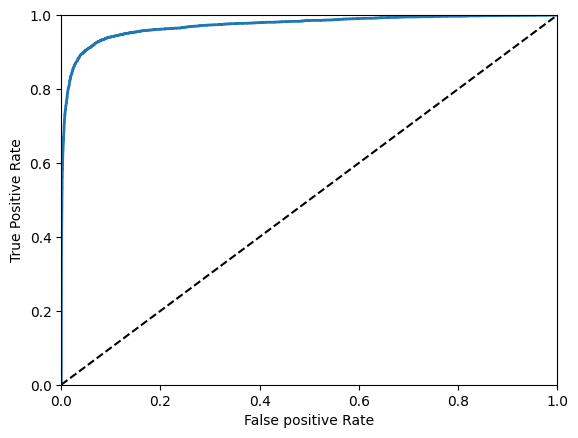

In [24]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0,1], [0,1], 'k--')
    plt.axis([0,1,0,1])
    plt.xlabel("False positive Rate")
    plt.ylabel("True Positive Rate")

plot_roc_curve(fpr, tpr, label='ROC curve')
plt.show()

In [25]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_tr_2, y_scores)

0.9725757510423648

Now trainig a Random forrest classifier, computing ROC and ROC AUC

In [26]:
from sklearn.ensemble import RandomForestClassifier

forst_clf = RandomForestClassifier(random_state=42)
y_probabs_foret = cross_val_predict(forst_clf, X_train, y_tr_2, cv=3, method='predict_proba')


In [27]:
## scores and not probabilities for ROC:
y_score_forest = y_probabs_foret[:, 1]
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_tr_2, y_score_forest)

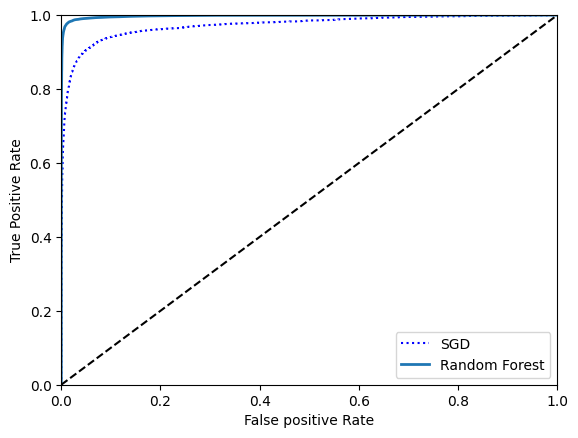

In [30]:
plt.plot(fpr, tpr, "b:", label='SGD')
plot_roc_curve(fpr_forest, tpr_forest, "Random Forest")
plt.legend(loc="lower right")
plt.show()


In [31]:
roc_auc_score(y_tr_2, y_score_forest)

0.9978662332166672

In [32]:
## trying ova
sgd_clf.fit(X_train, y_train)
sgd_clf.predict([some_digit])

array([7])

In [33]:
some_digit_scores = sgd_clf.decision_function([some_digit])
some_digit_scores 

array([[-19919.01652846, -14390.32309632,  -3273.19702381,
         -1824.54409994, -10477.02987321,  -6793.1718087 ,
        -19651.10063258,   4454.09891559,  -3947.39721872,
         -1528.74456258]])

In [34]:
np.argmax(some_digit_scores)

np.int64(7)

In [35]:
sgd_clf.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])